# Conductive drying – energy demand model

*Drying › Conductive drying* (manuscript Fig. 1)

**Examples** (Fig. 1). All use the same model; the examples change nothing in the equations.
| Process | Products |
|---|---|
| Belt drying | fruit pieces, vegetable flakes, pharmaceutical powders, ceramics |
| Textile drying | cotton and synthetic fabrics, towels and linens |
| Contact drum drying | paper, baby food, food pastes, gelatin, yeast extract |

The wet product is heated to the temperature of the heated plate, drum or belt and its moisture evaporates there. An air stream carries the vapour away; its outlet is cooled to $T_3$ like in convective drying (manuscript section *Conductive drying*, Fig. 4).

$$\dot Q_{sensible}=\dot m_{product}\,c_{p,wet}\,(T_{surface}-T_{inlet})\quad(10)\qquad \dot Q_{latent}=\dot m_{product}\,(w_{in}-w_{out})\,h_{v,water}\quad(11)$$
$$x_2=x_1+\frac{\dot m_{water}}{\dot m_{air}}\quad(5)\qquad \dot Q_{cooling}=\dot Q_{dew}+\dot Q_{latent}\quad(7)\text{–}(9)$$

This notebook holds no formulas of its own: it imports **`model.py`**, the model the app runs.

1. Example calculation
2. Figures and simplified P&ID (saved as `pid.svg`)
3. Validation against the manuscript and consistency checks
4. Comparison with an existing implementation

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, Circle, FancyBboxPatch, Polygon
from IPython.display import display, Markdown

try:
    import process_models
except ImportError:            # not installed: use the copy in this repository
    import sys
    sys.path.insert(0, str(Path.cwd().parents[1]))   # .../process_models (the folder holding the package)

from process_models import PROCESSES, run_process
from process_models.conductive_drying.model import MODEL, calculate

KEY = MODEL.key

pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
pd.set_option("display.max_colwidth", 90)
pd.set_option("display.width", 200)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3, "font.size": 10})


def show(res, audit):
    """Input table, results and stream data of one run."""
    display(Markdown("**Inputs** (required / optional, source of each value)"))
    display(pd.DataFrame(audit))
    for w in res.warnings:
        print("WARNING:", w)
    display(Markdown("**Results**"))
    display(pd.DataFrame(res.summary()))
    display(Markdown("**Stream data** (what the app hands to the pinch analysis)"))
    display(pd.DataFrame(res.stream_table()))


print(f"{MODEL.name} v{MODEL.version} | processes found by the app: {list(PROCESSES)}")

Conductive drying v1.0 | processes found by the app: ['autoclaving', 'conductive_drying', 'continuous_bath_heating', 'continuous_heating_of_fluid', 'convective_drying', 'thermal_phase_change']


## 1  Example calculation
Paper drying with the inputs of the manuscript (p. 18 and 20): 30,000 kg/h product, moisture 50 % → 7.5 %, air
106,250 kg/h at 15 °C and 6.43 g/kg, air outlet 70 °C, return 25 °C. Not given in the manuscript and **assumed**:
surface temperature 135 °C (sink of Fig. 12 at 140 °C shifted), product inlet 15 °C, $c_{p,wet}$ = 2.7 kJ/(kg K).

In [2]:
PAPER = dict(product_flow_kg_h=30000, w_in=0.5, w_out=0.075, T_surface=135, T_product_in=15, cp_wet=2.7,
             air_flow_kg_h=106250, T1=15, x1_g_kg=6.43, T2=70, T_return=25)
result, audit = run_process(KEY, **PAPER)
show(result, audit)

**Inputs** (required / optional, source of each value)

,Symbol,Input,Value,Unit,Type,Source,Manuscript / note
0,m_product,Product mass flow rate,"30,000.000",kg/h,required,user input,"Sect. 'Conductive drying', input list"
1,w_in,Initial moisture content of the product,0.500,kg/kg,required,user input,"Sect. 'Conductive drying', input list | Eq. (11): water evaporated = m_product * (w_in..."
2,w_out,Final moisture content of the product,0.075,kg/kg,required,user input,"Sect. 'Conductive drying', input list"
3,T_surface,Drying surface temperature,135.000,degC,required,user input,"Sect. 'Conductive drying', input list"
4,T_inlet,Product inlet temperature,15.000,degC,required,user input,"Eq. (10) | In Eq. (10), not in the input list."
5,"cp,wet",Specific heat capacity of the wet product,2.700,kJ/(kg K),required,user input,"Eq. (10) | In Eq. (10), not in the input list."
6,m_air,Air mass flow rate (dry air),"106,250.000",kg/h,required,user input,"Sect. 'Conductive drying', input list"
7,T1,Air inlet temperature,15.000,degC,required,user input,"Sect. 'Conductive drying', input list"
8,x1,Air inlet absolute humidity,6.430,g/kg,required,user input,"Sect. 'Conductive drying', input list"
9,T2,Air outlet temperature,70.000,degC,required,user input,"Sect. 'Conductive drying', text | 'must be known' (text), not in the input list."


**Results**

,Quantity,Symbol,Value,Unit,Manuscript ref.
0,Sensible heating of the wet product,m_product*cp_wet*(T_surface - T_inlet),"2,700.000",kW,Eq. (10)
1,Evaporation of the moisture,m_product*(w_in - w_out)*h_v,"7,724.552",kW,Eq. (11)
2,HEATING DEMAND (heated surface),Q_sensible + Q_latent,"10,424.552",kW,Eq. (10) + (11)
3,Water removed from the product,m_product*(w_in - w_out),"12,750.000",kg/h,Eq. (11)
4,Outlet air humidity,x2 = x1 + m_water/m_air,126.430,g/kg,Eq. (5)
5,Dew point of the outlet air,T_dew(x2),56.704,degC,-
6,Sensible cooling to the dew point,m_air*(h_outlet - h_dew),487.048,kW,Eq. (7)
7,Latent cooling (condensation),m_air*(h_dew - h_return),"9,161.753",kW,Eq. (8)
8,COOLING DEMAND (outlet air),Q_dew + Q_latent,"9,648.800",kW,Eq. (9)
9,Condensate,m_air*(x2 - x3),"11,305.745",kg/h,-


**Stream data** (what the app hands to the pinch analysis)

,stream,type,T_supply_degC,T_target_degC,CP_kW_per_K,Q_kW
0,product heating,cold,15.000,135.000,22.500,"2,700.000"
1,evaporation at the surface,cold,135.000,136.000,"7,724.552","7,724.552"
2,"exhaust air, sensible",hot,70.000,56.704,36.631,487.048
3,"exhaust air, condensation",hot,56.704,25.000,288.977,"9,161.753"


## 2  Figures and simplified P&ID

In [3]:
def plot_demand_breakdown(res):
    """Every kW quantity of the results table; totals dark."""
    rows = [r for r in res.summary() if r["Unit"] == "kW"][::-1]
    fig, ax = plt.subplots(figsize=(9, 0.45 * len(rows) + 1.4))
    colors = ["#333333" if r["Quantity"].split(" (")[0].isupper() else "#4c78a8" for r in rows]
    bars = ax.barh([r["Quantity"] for r in rows], [r["Value"] for r in rows], color=colors)
    for b, r in zip(bars, rows):
        ax.annotate(f"{r['Value']:,.1f} kW", (b.get_width(), b.get_y() + b.get_height() / 2),
                    xytext=(4, 0), textcoords="offset points", va="center", fontsize=8)
    ax.set(xlabel="Thermal power [kW]", title=f"Energy demand: {MODEL.name}")
    ax.margins(x=0.2)
    fig.tight_layout()
    return fig


def plot_stream_data(res):
    """Streams handed to the pinch analysis, stacked by heat flow: cold blue, hot red."""
    fig, ax = plt.subplots(figsize=(8, 4.6))
    q, temps = {"cold": 0.0, "hot": 0.0}, []
    for s in res.stream_table():
        q0 = q[s["type"]]
        q[s["type"]] = q1 = q0 + s["Q_kW"]
        color = "tab:blue" if s["type"] == "cold" else "tab:red"
        ax.annotate("", xy=(q1, s["T_target_degC"]), xytext=(q0, s["T_supply_degC"]),
                    arrowprops=dict(arrowstyle="-|>", color=color, lw=2, mutation_scale=14))
        ax.text((q0 + q1) / 2, (s["T_supply_degC"] + s["T_target_degC"]) / 2, "  " + s["stream"],
                color=color, fontsize=8, va="bottom")
        temps += [s["T_supply_degC"], s["T_target_degC"]]
    qmax = max(q.values()) or 1.0
    ax.set_xlim(-0.02 * qmax, 1.1 * qmax)
    ax.set_ylim(min(temps) - 10, max(temps) + 10)
    ax.set(xlabel="Heat flow [kW]", ylabel="Temperature [degC]", title="Stream data (cold: blue, hot: red)")
    fig.tight_layout()
    return fig


def plot_sensitivity(res, sweeps):
    """One-at-a-time sensitivity of the heating and cooling demand."""
    fig, axes = plt.subplots(1, len(sweeps), figsize=(6 * len(sweeps), 4), squeeze=False)
    for ax, (param, grid, xlabel) in zip(axes[0], sweeps):
        rows = []
        for x in grid:
            try:
                r = calculate({**res.inputs, param: float(x)})
                rows.append((x, r.Q_heating, r.Q_cooling))
            except ValueError:
                continue
        xs, qh, qc = zip(*rows)
        ax.plot(xs, qh, label="heating demand")
        if any(qc):
            ax.plot(xs, qc, label="cooling demand")
        ax.axvline(res.inputs[param], color="grey", ls="--", lw=0.8)
        ax.set(xlabel=xlabel, ylabel="Thermal power [kW]")
        ax.legend(fontsize=8)
    fig.suptitle("Sensitivity (one parameter varied, all others fixed)")
    fig.tight_layout()
    return fig



SWEEPS = [("T_surface", np.linspace(100, 180, 33), "Surface temperature [degC]"),
          ("w_out", np.linspace(0.02, 0.3, 29), "Final moisture content w_out [-]")]

In [4]:
class Sketch:
    """Small drawing kit for the simplified P&IDs (ISA-5.1 style tags)."""

    def __init__(self, ax, lw=1.8):
        self.ax, self.lw = ax, lw

    def line(self, xs, ys, ls="-", lw=None, color="k"):
        self.ax.plot(xs, ys, ls=ls, lw=lw or self.lw, color=color, solid_capstyle="butt", zorder=2)

    def arrow(self, x0, y0, x1, y1, color="k"):
        self.ax.annotate("", xy=(x1, y1), xytext=(x0, y0), zorder=3,
                         arrowprops=dict(arrowstyle="-|>", lw=self.lw, color=color, mutation_scale=14))

    def text(self, x, y, s, **kw):
        kw.setdefault("fontsize", 9); kw.setdefault("ha", "center"); kw.setdefault("va", "center")
        self.ax.text(x, y, s, **kw)

    def hx(self, x, y, r=0.55):
        """Heat exchanger: circle with zigzag."""
        self.ax.add_patch(Circle((x, y), r, fc="white", ec="k", lw=1.6, zorder=4))
        self.ax.plot(np.linspace(x - 0.42, x + 0.42, 7), y + 0.14 * np.array([0, 1, -1, 1, -1, 1, 0]),
                     color="k", lw=1.3, zorder=5)

    def box(self, x, y, w, h, s="", fc="#eef3f8", rounded=False, fontsize=8.5):
        patch = (FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.02,rounding_size=0.3", fc=fc, ec="k", lw=1.6, zorder=3)
                 if rounded else Rectangle((x, y), w, h, fc=fc, ec="k", lw=1.6, zorder=3))
        self.ax.add_patch(patch)
        if s:
            self.text(x + w / 2, y + h / 2, s, fontsize=fontsize, zorder=4)

    def pump(self, x, y, tag, r=0.45):
        """Pump or fan."""
        self.ax.add_patch(Circle((x, y), r, fc="white", ec="k", lw=1.6, zorder=4))
        self.ax.add_patch(Polygon([(x - .2, y - .28), (x - .2, y + .28), (x + .3, y)], fc="k", zorder=5))
        self.text(x, y - r - 0.3, tag)

    def bubble(self, x, y, tag, num, value=None, r=0.42, below=False):
        """Instrument bubble with tag, loop number and the value it measures or controls."""
        self.ax.add_patch(Circle((x, y), r, fc="white", ec="k", lw=1.4, zorder=5))
        self.text(x, y + 0.1, tag, fontsize=8.5, fontweight="bold", zorder=6)
        self.text(x, y - 0.16, num, fontsize=8, zorder=6)
        if value is not None:
            self.text(x, y - r - 0.25 if below else y + r + 0.25, value, color="firebrick", fontweight="bold")

    def valve_h(self, x, y):
        """Control valve on a horizontal line, actuator on top."""
        for sgn in (+1, -1):
            self.ax.add_patch(Polygon([(x + sgn * .22, y + .25), (x + sgn * .22, y - .25), (x, y)],
                                      fc="white", ec="k", lw=1.4, zorder=5))
        self.ax.plot([x, x], [y, y + 0.45], color="k", lw=1.2, zorder=5)
        self.ax.add_patch(Circle((x, y + 0.65), 0.2, fc="white", ec="k", lw=1.2, zorder=5))

    def valve_v(self, x, y, side=+1):
        """Control valve on a vertical line, actuator to the side."""
        for sgn in (+1, -1):
            self.ax.add_patch(Polygon([(x - .25, y + sgn * .22), (x + .25, y + sgn * .22), (x, y)],
                                      fc="white", ec="k", lw=1.4, zorder=5))
        self.ax.plot([x, x + side * 0.45], [y, y], color="k", lw=1.2, zorder=5)
        self.ax.add_patch(Circle((x + side * 0.65, y), 0.2, fc="white", ec="k", lw=1.2, zorder=5))

    def signal(self, xs, ys):
        self.line(xs, ys, ls=":", lw=1.1)


FOOT = "Simplified P&ID (ISA-5.1 style tags), generated from the demand model - not for construction."


def new_pid(title, ymin=-1.3, ymax=9.6):
    fig, ax = plt.subplots(figsize=(16, 16 * (ymax - ymin) / 20))
    ax.set_xlim(0, 20); ax.set_ylim(ymin, ymax); ax.set_aspect("equal"); ax.axis("off")
    ax.set_title(title, fontsize=12)
    return fig, ax, Sketch(ax)


def footer(ax, s):
    ax.text(0.3, ax.get_ylim()[0] + 0.05, s, fontsize=8.5, color="dimgrey", va="bottom")

In [5]:
def draw_pid(res):
    """Simplified P&ID of a contact dryer (steam heated cylinders) with hood air and exhaust air cooler."""
    v = res.inputs
    fig, ax, s = new_pid("Conductive drying (contact dryer) - simplified P&ID")
    yp = 2.9
    # ---- dryer with heated cylinders and hood --------------------------------------------------
    s.box(6.0, 2.2, 5.0, 3.0, fc="white")
    for xc in (7.0, 8.5, 10.0):
        ax.add_patch(Circle((xc, 3.7), 0.6, fc="#f3e3d3", ec="k", lw=1.3, zorder=4))
    s.text(8.5, 4.75, f"D-101 Contact dryer, T_surface = {v['T_surface']:.0f} degC", zorder=5)
    ax.add_patch(Polygon([(6.0, 5.2), (11.0, 5.2), (10.4, 6.0), (6.6, 6.0)], fc="#eef3f8", ec="k", lw=1.6, zorder=3))
    s.text(8.5, 5.6, "hood", fontsize=8, zorder=4)
    # ---- product -------------------------------------------------------------------------------
    s.box(0.1, yp - 0.6, 2.4, 1.2, f"T-101 Wet product\n{v['product_flow_kg_h']:,.0f} kg/h\nw_in = {v['w_in']:.3f}")
    s.line([2.5, 6.0], [yp, yp]); s.arrow(3.4, yp, 3.8, yp)
    s.line([6.0, 11.0], [yp, yp], lw=1.2)
    s.line([11.0, 13.6], [yp, yp]); s.arrow(12.2, yp, 12.6, yp)
    s.box(13.6, yp - 0.6, 2.5, 1.2, f"T-102 Dry product\nw_out = {v['w_out']:.3f}")
    s.signal([4.8, 4.8], [yp, yp + 0.58]); s.bubble(4.8, yp + 1.0, "TI", "101", f"{v['T_product_in']:.0f} degC")
    # ---- steam to the cylinders ------------------------------------------------------------------
    s.line([7.6, 7.6], [0.0, 2.2]); s.line([9.4, 9.4], [2.2, 0.0]); s.arrow(7.6, 0.2, 7.6, 0.6)
    s.valve_v(7.6, 1.2, side=-1)
    s.text(7.6, -0.25, "steam in", fontsize=7.5); s.text(9.4, -0.25, "condensate", fontsize=7.5)
    s.bubble(5.6, 1.2, "TIC", "101", f"{v['T_surface']:.0f} degC", below=True)
    s.line([6.02, 6.75], [1.2, 1.2], ls="--", lw=1.1)
    s.text(9.7, 1.2, f"Heating Q = {res.Q_heating:,.1f} kW\n(product {res.Q_sensible:,.0f} + evaporation {res.Q_latent_heating:,.0f} kW)",
           ha="left")
    # ---- air through the hood ------------------------------------------------------------------
    s.box(0.3, 5.0, 1.9, 1.2, f"Air in\nT1 = {v['T1']:.0f} degC\nx1 = {v['x1_g_kg']:.2f} g/kg", rounded=True)
    s.line([2.2, 2.75], [5.6, 5.6]); s.pump(3.2, 5.6, "F-101 Fan"); s.line([3.65, 6.3], [5.6, 5.6]); s.arrow(4.6, 5.6, 5.0, 5.6)
    # ---- exhaust air cooler ----------------------------------------------------------------------
    s.line([9.6, 9.6], [6.0, 7.2]); s.line([9.6, 12.05], [7.2, 7.2]); s.arrow(10.2, 7.2, 10.6, 7.2); s.hx(12.6, 7.2)
    s.line([12.6, 12.6], [7.75, 8.0]); s.text(12.6, 8.15, "cold utility", fontsize=7.5)
    s.text(13.3, 8.35, f"E-101 Exhaust air cooler\nQ = {res.Q_cooling:,.1f} kW", ha="left")
    s.line([12.6, 12.6], [6.65, 6.0]); s.arrow(12.6, 6.3, 12.6, 5.95)
    s.text(12.6, 5.6, f"condensate\n{res.condensate_kg_h:,.0f} kg/h", fontsize=7.5)
    s.line([13.15, 15.6], [7.2, 7.2]); s.arrow(14.6, 7.2, 15.0, 7.2)
    s.box(15.6, 6.6, 2.0, 1.2, f"Air out\nT3 = {v['T_return']:.0f} degC")
    s.signal([11.0, 11.0], [7.2, 7.78]); s.bubble(11.0, 8.2, "TI", "102", f"T2 = {v['T2']:.0f} degC")
    footer(ax, FOOT + " Heat recovery is not modelled.\n"
           f"water removed = {res.water_removed_kg_h:,.0f} kg/h, x2 = {res.x2 * 1000:.1f} g/kg, dew point {res.T_dew:.1f} degC, "
           f"h_v = {v['h_v']:,.0f} kJ/kg")
    return fig

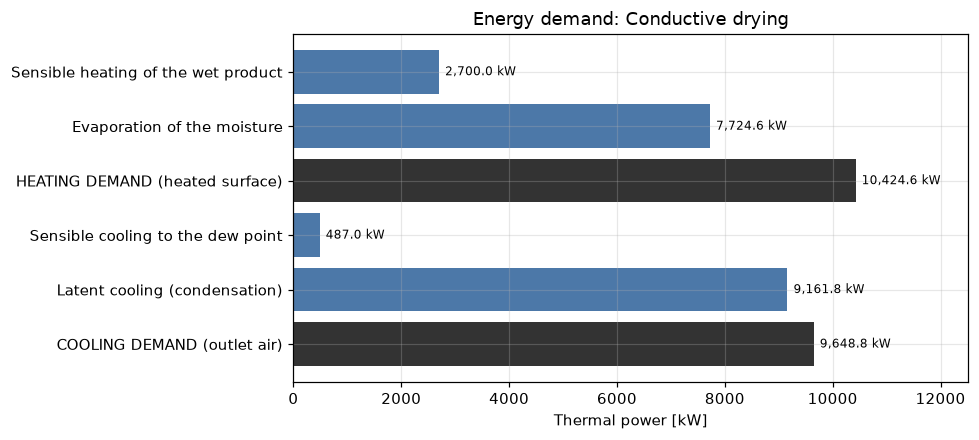

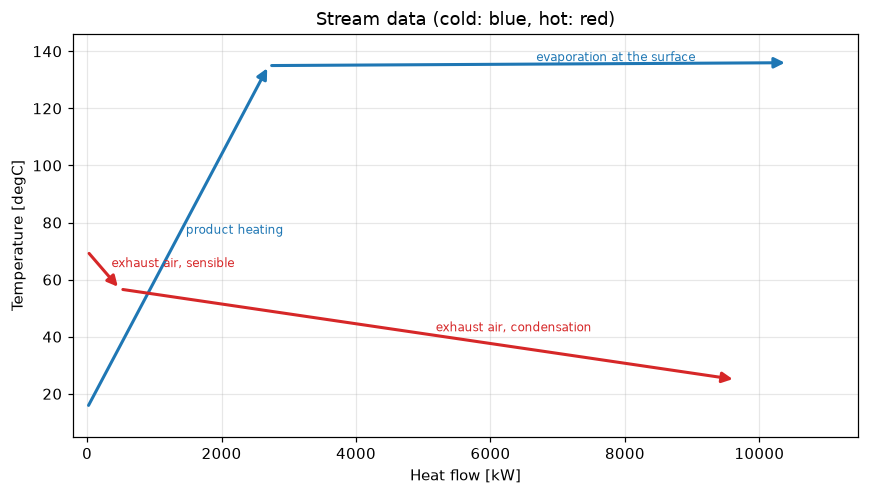

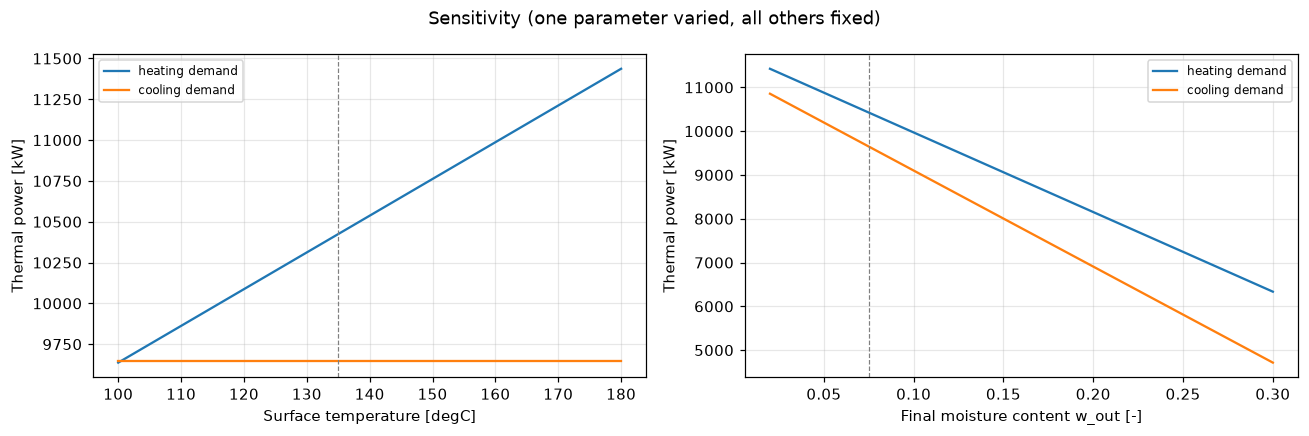

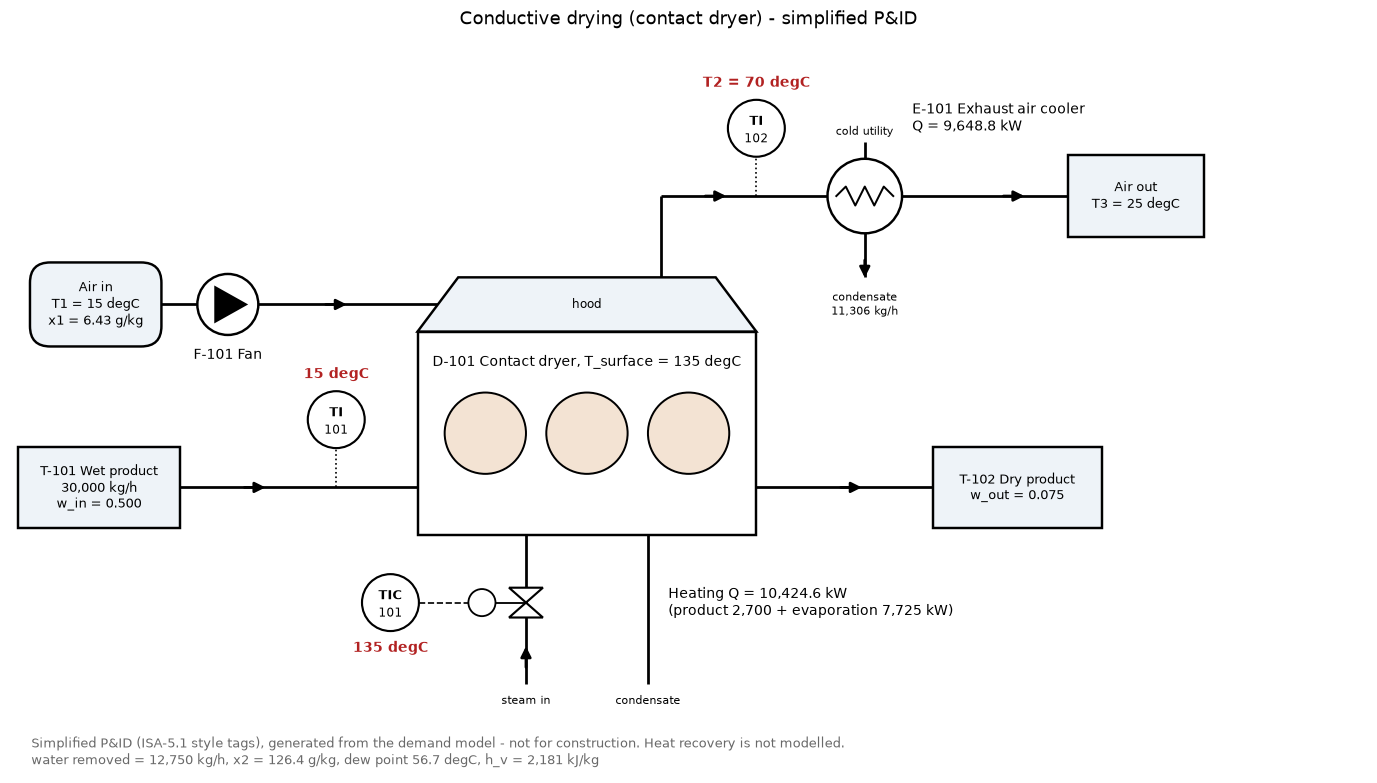

In [6]:
for fig in (plot_demand_breakdown(result), plot_stream_data(result), plot_sensitivity(result, SWEEPS)):
    plt.show()

fig = draw_pid(result)
fig.savefig("pid.svg", bbox_inches="tight")   # P&ID of the example, kept next to model.py
plt.show()

## 3  Validation against the manuscript
Paper drying, operational data of a paper factory (reference [24]), manuscript p. 18 (Table 2) and p. 20:

| | Model (manuscript) | Reference |
|---|---|---|
| Energy demand | 9,472.00 kW | 9,996.25 kW |
| Outlet temperature | 70.2 °C | 70.0 °C |
| Outlet moisture | 121.2 g/kg | 120.0 g/kg |
| Evaporation energy demand (p. 20) | 7,724 kW | – |
| Cooling energy of the exhaust air (p. 20) | 2,227 kW | – |

**Points found in the manuscript (please check):**
1. **Evaporation demand reproduced:** Eq. (11) with $h_{v}$ of water at 135 °C (2,181 kJ/kg) gives 7,724.6 kW.
2. **Energy demand:** surface temperature, product inlet temperature and $c_{p,wet}$ are not given. With 135 °C and
   15 °C, the 9,472 kW need $c_{p,wet}$ = 1.75 kJ/(kg K) (below).
3. **Outlet moisture:** the reference 120.0 g/kg is exactly the water taken up, $\dot m_{water}/\dot m_{air}$, without the
   inlet humidity; Eq. (5) gives 126.4 g/kg. The manuscript model value 121.2 g/kg does not follow from Eq. (5).
4. **Cooling:** Eq. (7)–(9) from 70 °C to 25 °C give about 9,650 kW (mostly condensation), not 2,227 kW.
5. The outlet temperature $T_2$ is an input ("must be known"), so 70.2 °C vs 70.0 °C cannot be checked here.
6. The heating of the air from $T_1$ to $T_2$ inside the dryer is not part of Eq. (10)/(11).
7. The printed RMSE is 525.25 kW, but $|9{,}472.00 - 9{,}996.25|$ = 524.25 kW (one data point).

In [7]:
REF = dict(Q_model=9472.00, Q_ref=9996.25, x_model=121.2, x_ref=120.0, Q_evap=7724, Q_cool=2227)
m = PAPER["product_flow_kg_h"] / 3600
cp_needed = (REF["Q_model"] - result.Q_latent_heating) / (m * (PAPER["T_surface"] - PAPER["T_product_in"]))
display(pd.DataFrame([
    ("Evaporation demand, Eq. (11) [kW]", result.Q_latent_heating, REF["Q_evap"], None),
    ("Energy demand, Eq. (10) + (11) [kW]", result.Q_heating, REF["Q_model"], REF["Q_ref"]),
    ("Outlet moisture x2, Eq. (5) [g/kg]", result.x2 * 1000, REF["x_model"], REF["x_ref"]),
    ("Water taken up, x2 - x1 [g/kg]", (result.x2 - result.x1) * 1000, REF["x_model"], REF["x_ref"]),
    ("Cooling of the exhaust air, Eq. (9) [kW]", result.Q_cooling, REF["Q_cool"], None),
], columns=["Quantity", "This model", "Manuscript model", "Reference"]))
print(f"c_p,wet needed for 9,472 kW (T_surface 135, T_inlet 15 degC): {cp_needed:.3f} kJ/(kg K)")
dev = abs(REF["Q_model"] - REF["Q_ref"])
print(f"Manuscript: |{REF['Q_model']} - {REF['Q_ref']}| = {dev:.2f} kW (RMSE 525.25), {dev / REF['Q_model']:.2%} of the model value")

# ---- consistency checks -----------------------------------------------------------------------
assert abs(result.Q_latent_heating - REF["Q_evap"]) < 1                                   # point 1
assert abs((result.x2 - result.x1) * 1000 - REF["x_ref"]) < 0.01                          # point 3
r_cp, _ = run_process(KEY, **{**PAPER, "cp_wet": cp_needed})
assert abs(r_cp.Q_heating - REF["Q_model"]) < 1e-6                                        # point 2
st = result.stream_table()
assert abs(sum(s["Q_kW"] for s in st if s["type"] == "cold") - result.Q_heating) < 1e-6
assert abs(sum(s["Q_kW"] for s in st if s["type"] == "hot") - result.Q_cooling) < 1e-6
print("All consistency checks passed.")

,Quantity,This model,Manuscript model,Reference
0,"Evaporation demand, Eq. (11) [kW]","7,724.552","7,724.000",NaN
1,"Energy demand, Eq. (10) + (11) [kW]","10,424.552","9,472.000","9,996.250"
2,"Outlet moisture x2, Eq. (5) [g/kg]",126.430,121.200,120.000
3,"Water taken up, x2 - x1 [g/kg]",120.000,121.200,120.000
4,"Cooling of the exhaust air, Eq. (9) [kW]","9,648.800","2,227.000",NaN


c_p,wet needed for 9,472 kW (T_surface 135, T_inlet 15 degC): 1.747 kJ/(kg K)
Manuscript: |9472.0 - 9996.25| = 524.25 kW (RMSE 525.25), 5.53% of the model value
All consistency checks passed.


## 4  Comparison with an existing implementation
Not possible yet: the original notebook (`continuous_heating_of_fluid/energy_demand_models_notebook_1.ipynb`) only lists
this process as *planned*; the legacy `classes.ConductiveDrying` it mentions (with fixed 1200 J/(kg K) and 85 K)
is not in the repository.